# Chapter 2: Crypto Market Data — OHLCV, Funding & the DuckDB Pipeline

*ML for Digital Assets — adapted from Jansen’s Machine Learning for Algorithmic Trading*

This notebook introduces the market-data foundation that powers every model in later chapters.
We cover:

1. **Connecting to `market.duckdb`** and inspecting available tables/views
2. **Loading and visualizing** hourly, 4-hour, and daily bars for BTC-USD and ETH-USD
3. **Resampling rules** — how OHLCV and funding rates aggregate across timeframes
4. **Timestamp integrity checks** and duplicate remediation
5. **Look-ahead lag diagnostics** — ensuring no future data leaks into past bars
6. **Native vs resampled timeframe comparison** — when does resampling diverge?
7. **A reusable data-loading utility** for downstream chapters

---
## 0. Setup — Build the synthetic DuckDB lake

The production lake lives at `COINBASE_LAKE` and is loaded via `ml4t_crypto.load_bars()`.
For this standalone walkthrough, we generate a year of synthetic OHLCV + funding-rate
data for **BTC-USD** and **ETH-USD** across three timeframes (`1h`, `4h`, `1d`),
stored in a local `data/market.duckdb`.

In [1]:
from __future__ import annotations

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="muted")
pd.options.display.float_format = "{:,.4f}".format

DB_PATH = Path("../data/market.duckdb")
DB_PATH.parent.mkdir(parents=True, exist_ok=True)
print(f"DuckDB path: {DB_PATH.resolve()}")

DuckDB path: /home/user/ml_4_da/data/market.duckdb


In [2]:
# ---------- synthetic data generator ----------
def generate_bars(
    symbol: str, start_price: float, volatility: float,
    freq: str, start: str, end: str, seed: int = 42,
) -> pd.DataFrame:
    """Generate synthetic OHLCV + funding_rate bars."""
    rng = np.random.default_rng(seed + hash(symbol) % 10_000 + hash(freq) % 10_000)
    timestamps = pd.date_range(start, end, freq=freq, tz="UTC")
    n = len(timestamps)

    returns = rng.normal(0.0002, volatility, n)
    close = start_price * np.exp(np.cumsum(returns))

    spread = volatility * close
    high  = close + rng.uniform(0, 1, n) * spread
    low   = close - rng.uniform(0, 1, n) * spread
    open_ = np.roll(close, 1) + rng.normal(0, spread * 0.1)
    open_[0] = start_price

    high = np.maximum(high, np.maximum(open_, close))
    low  = np.minimum(low,  np.minimum(open_, close))

    volume = rng.lognormal(mean=15, sigma=1.5, size=n)
    if "BTC" in symbol:
        volume *= 10

    funding_rate = rng.normal(0.0001, 0.0003, n)

    return pd.DataFrame({
        "timestamp": timestamps,
        "symbol": symbol,
        "open":  np.round(open_, 2),
        "high":  np.round(high, 2),
        "low":   np.round(low, 2),
        "close": np.round(close, 2),
        "volume":       np.round(volume, 4),
        "funding_rate": np.round(funding_rate, 6),
    })


# ---------- seed the lake ----------
SYMBOLS = {
    "BTC-USD": {"start_price": 42_000, "vol": 0.02},
    "ETH-USD": {"start_price": 2_200,  "vol": 0.025},
}
START, END = "2024-01-01", "2024-12-31"
FREQ_MAP = {"1h": "1h", "4h": "4h", "1d": "1D"}

con = duckdb.connect(str(DB_PATH), read_only=False)

for tf in FREQ_MAP:
    con.execute(f"""
        CREATE OR REPLACE TABLE bars_{tf} (
            timestamp TIMESTAMPTZ NOT NULL,
            symbol    VARCHAR     NOT NULL,
            open      DOUBLE, high DOUBLE, low DOUBLE, close DOUBLE,
            volume    DOUBLE, funding_rate DOUBLE,
            PRIMARY KEY (timestamp, symbol)
        )
    """)
    for sym, p in SYMBOLS.items():
        df = generate_bars(sym, p["start_price"], p["vol"],
                           FREQ_MAP[tf], START, END)
        con.execute(f"INSERT INTO bars_{tf} SELECT * FROM df")
        print(f"  bars_{tf}/{sym}: {len(df):,} bars")

# Summary view
con.execute("""
    CREATE OR REPLACE VIEW bar_summary AS
    SELECT 'bars_1h' AS tbl, symbol, COUNT(*) AS n,
           MIN(timestamp) AS first_ts, MAX(timestamp) AS last_ts FROM bars_1h GROUP BY symbol
    UNION ALL
    SELECT 'bars_4h', symbol, COUNT(*), MIN(timestamp), MAX(timestamp) FROM bars_4h GROUP BY symbol
    UNION ALL
    SELECT 'bars_1d', symbol, COUNT(*), MIN(timestamp), MAX(timestamp) FROM bars_1d GROUP BY symbol
    ORDER BY tbl, symbol
""")
con.close()
print("\nDone.")

  bars_1h/BTC-USD: 8,761 bars
  bars_1h/ETH-USD: 8,761 bars
  bars_4h/BTC-USD: 2,191 bars
  bars_4h/ETH-USD: 2,191 bars
  bars_1d/BTC-USD: 366 bars
  bars_1d/ETH-USD: 366 bars

Done.


---
## 1. Connecting to `market.duckdb` & inspecting available tables

In [3]:
con = duckdb.connect(str(DB_PATH), read_only=True)

tables = con.execute("""
    SELECT table_name, table_type
    FROM information_schema.tables
    WHERE table_schema = 'main'
    ORDER BY table_type, table_name
""").fetchdf()

print("Tables and views in market.duckdb:\n")
tables

Tables and views in market.duckdb:



,table_name,table_type
0,bars_1d,BASE TABLE
1,bars_1h,BASE TABLE
2,bars_4h,BASE TABLE
3,bar_summary,VIEW


In [4]:
# Quick summary: row counts, date range, symbols per table
con.execute("SELECT * FROM bar_summary").fetchdf()

,tbl,symbol,n,first_ts,last_ts
0,bars_1d,BTC-USD,366,2024-01-01 00:00:00+00:00,2024-12-31 00:00:00+00:00
1,bars_1d,ETH-USD,366,2024-01-01 00:00:00+00:00,2024-12-31 00:00:00+00:00
2,bars_1h,BTC-USD,8761,2024-01-01 00:00:00+00:00,2024-12-31 00:00:00+00:00
3,bars_1h,ETH-USD,8761,2024-01-01 00:00:00+00:00,2024-12-31 00:00:00+00:00
4,bars_4h,BTC-USD,2191,2024-01-01 00:00:00+00:00,2024-12-31 00:00:00+00:00
5,bars_4h,ETH-USD,2191,2024-01-01 00:00:00+00:00,2024-12-31 00:00:00+00:00


In [5]:
# Schema of the bars_1h table
con.execute("DESCRIBE bars_1h").fetchdf()

,column_name,column_type,null,key,default,extra
0,timestamp,TIMESTAMP WITH TIME ZONE,NO,PRI,None,None
1,symbol,VARCHAR,NO,PRI,None,None
2,open,DOUBLE,YES,NaN,None,None
3,high,DOUBLE,YES,NaN,None,None
4,low,DOUBLE,YES,NaN,None,None
5,close,DOUBLE,YES,NaN,None,None
6,volume,DOUBLE,YES,NaN,None,None
7,funding_rate,DOUBLE,YES,NaN,None,None


In [6]:
# Peek at a few rows
con.execute("SELECT * FROM bars_1h WHERE symbol='BTC-USD' LIMIT 5").fetchdf()

,timestamp,symbol,open,high,low,close,volume,funding_rate
0,2024-01-01 00:00:00+00:00,BTC-USD,"42,000.0000","43,643.1900","42,000.0000","43,051.5500","1,028,335,714.3449",0.0006
1,2024-01-01 01:00:00+00:00,BTC-USD,"43,143.2600","43,790.5600","42,706.0800","43,042.1900","319,919,101.7442",0.0001
2,2024-01-01 02:00:00+00:00,BTC-USD,"43,075.7400","43,570.8200","42,643.3400","43,313.7200","261,350,489.0121",0.0003
3,2024-01-01 03:00:00+00:00,BTC-USD,"43,347.6100","43,347.6100","42,574.2700","42,911.2200","85,223,972.9584",0.0003
4,2024-01-01 04:00:00+00:00,BTC-USD,"42,885.7700","43,505.5000","42,468.5300","43,066.1200","112,645,781.1299",-0.0007


---
## 2. Loading and visualizing bars (1h, 4h, 1d)

We load BTC-USD and ETH-USD at each granularity and build a multi-panel
comparison of price and volume.

In [7]:
def load_bars_from_db(
    table: str,
    symbol: str | None = None,
    start: str | None = None,
    end: str | None = None,
    con: duckdb.DuckDBPyConnection | None = None,
) -> pd.DataFrame:
    """Load OHLCV+funding bars from the DuckDB lake."""
    own = con is None
    if own:
        con = duckdb.connect(str(DB_PATH), read_only=True)
    clauses = ["1=1"]
    if symbol:  clauses.append(f"symbol = '{symbol}'")
    if start:   clauses.append(f"timestamp >= '{start}'")
    if end:     clauses.append(f"timestamp <= '{end}'")
    query = f"SELECT * FROM {table} WHERE {' AND '.join(clauses)} ORDER BY symbol, timestamp"
    df = con.execute(query).fetchdf()
    if own:
        con.close()
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
        df = df.set_index("timestamp")
    return df


# Load a month of data at each granularity for BTC-USD
btc_1h = load_bars_from_db("bars_1h", "BTC-USD", "2024-03-01", "2024-03-31")
btc_4h = load_bars_from_db("bars_4h", "BTC-USD", "2024-03-01", "2024-03-31")
btc_1d = load_bars_from_db("bars_1d", "BTC-USD", "2024-03-01", "2024-03-31")

print(f"BTC-USD 1h: {len(btc_1h):,} bars  |  4h: {len(btc_4h):,} bars  |  1d: {len(btc_1d):,} bars")

BTC-USD 1h: 721 bars  |  4h: 181 bars  |  1d: 31 bars


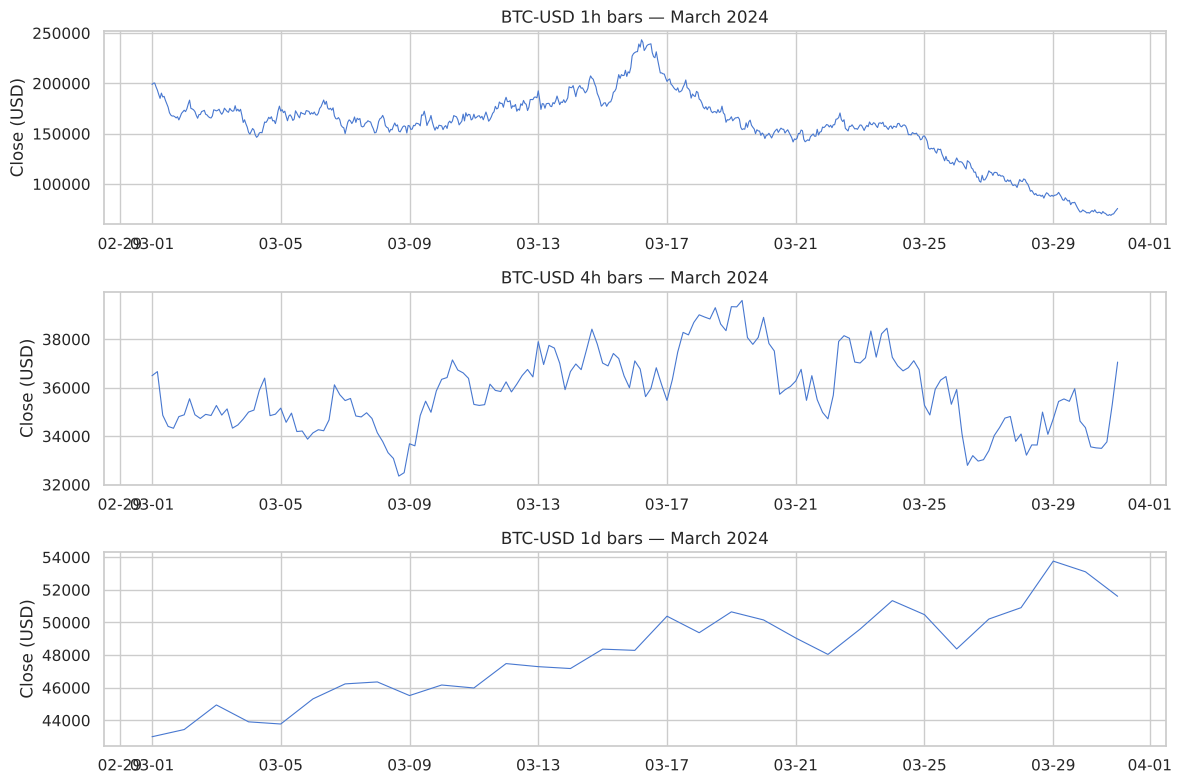

In [8]:
# Multi-panel: BTC-USD close across three timeframes
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=False)

for ax, (label, data) in zip(axes, [("1h", btc_1h), ("4h", btc_4h), ("1d", btc_1d)]):
    ax.plot(data.index, data["close"], lw=0.8)
    ax.set_ylabel("Close (USD)")
    ax.set_title(f"BTC-USD {label} bars — March 2024")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))

plt.tight_layout()
plt.show()

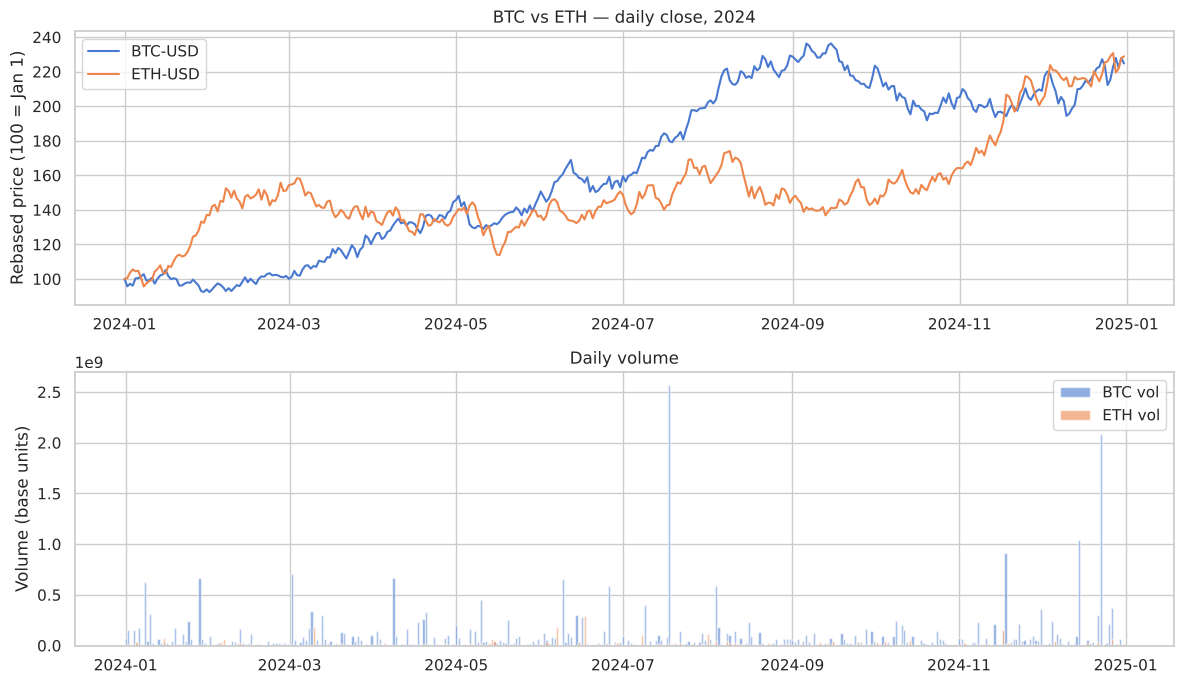

In [9]:
# BTC vs ETH: full-year daily close, normalized to 100 at the start
btc_d = load_bars_from_db("bars_1d", "BTC-USD")
eth_d = load_bars_from_db("bars_1d", "ETH-USD")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7))

# Price (rebased)
ax1.plot(btc_d.index, 100 * btc_d["close"] / btc_d["close"].iloc[0], label="BTC-USD")
ax1.plot(eth_d.index, 100 * eth_d["close"] / eth_d["close"].iloc[0], label="ETH-USD")
ax1.set_ylabel("Rebased price (100 = Jan 1)")
ax1.set_title("BTC vs ETH — daily close, 2024")
ax1.legend()

# Volume
ax2.bar(btc_d.index, btc_d["volume"], width=0.8, alpha=0.6, label="BTC vol")
ax2.bar(eth_d.index, eth_d["volume"], width=0.8, alpha=0.6, label="ETH vol")
ax2.set_ylabel("Volume (base units)")
ax2.set_title("Daily volume")
ax2.legend()

plt.tight_layout()
plt.show()

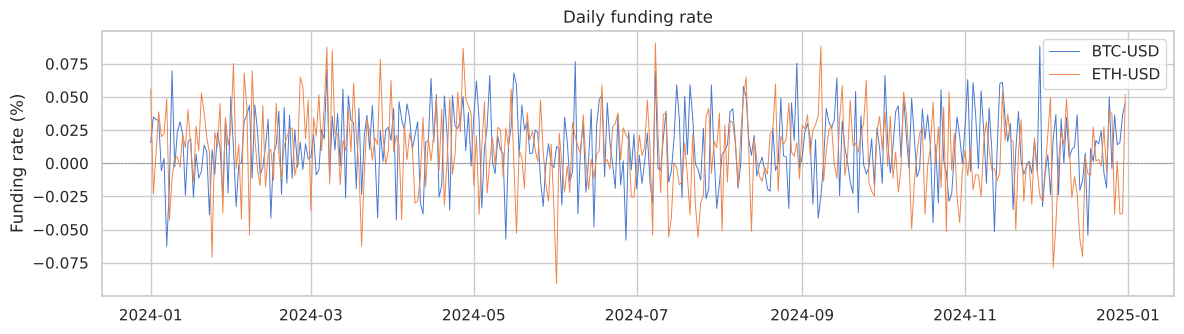

In [10]:
# Funding rate timeseries
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(btc_d.index, btc_d["funding_rate"] * 100, lw=0.7, label="BTC-USD")
ax.plot(eth_d.index, eth_d["funding_rate"] * 100, lw=0.7, label="ETH-USD")
ax.axhline(0, color="grey", ls="--", lw=0.5)
ax.set_ylabel("Funding rate (%)")
ax.set_title("Daily funding rate")
ax.legend()
plt.tight_layout()
plt.show()

---
## 3. Resampling rules

When aggregating finer bars to coarser ones, each field has a natural rule:

| Field | Rule | Why |
|---|---|---|
| `open` | **first** | The open of the period is the first trade’s open |
| `high` | **max** | The period’s high is the highest sub-period high |
| `low` | **min** | The period’s low is the lowest sub-period low |
| `close` | **last** | The close of the period is the last trade’s close |
| `volume` | **sum** | Volume is *extensive* — additive over time |
| `funding_rate` | **mean** | Funding is *intensive* — a rate per period; averaging preserves magnitude |

Volume must be **summed** because it measures total quantity traded (like distance).
Funding rate must be **averaged** because it’s a rate per unit time (like speed).
If you sum funding rates, you get the *cumulative funding paid*; if you average
them, you get the *typical rate* over the window.

In [11]:
OHLCV_AGG = {
    "open":  "first",
    "high":  "max",
    "low":   "min",
    "close": "last",
    "volume": "sum",
}


def resample_bars(
    df: pd.DataFrame,
    rule: str,
    funding_agg: str = "mean",
) -> pd.DataFrame:
    """Resample OHLCV+funding bars to a coarser timeframe."""
    agg = {**OHLCV_AGG}
    if "funding_rate" in df.columns:
        agg["funding_rate"] = funding_agg

    cols_present = {k: v for k, v in agg.items() if k in df.columns}

    if "symbol" in df.columns:
        result = df.groupby("symbol").resample(rule).agg(cols_present)
        result = result.reset_index(level="symbol")
    else:
        result = df.resample(rule).agg(cols_present)

    return result.dropna(subset=["close"])

In [12]:
# Resample 1h -> 4h for BTC-USD and compare to native 4h
btc_1h_full = load_bars_from_db("bars_1h", "BTC-USD")
btc_1h_no_sym = btc_1h_full.drop(columns=["symbol"])

resampled_4h = resample_bars(btc_1h_no_sym, "4h")
native_4h    = load_bars_from_db("bars_4h", "BTC-USD").drop(columns=["symbol"])

print(f"Resampled 1h->4h: {len(resampled_4h):,} bars")
print(f"Native 4h:        {len(native_4h):,} bars")
print()
print("First 5 resampled bars:")
resampled_4h.head()

Resampled 1h->4h: 2,191 bars
Native 4h:        2,191 bars

First 5 resampled bars:


,open,high,low,close,volume,funding_rate
timestamp,,,,,,
2024-01-01 00:00:00+00:00,"42,000.0000","43,790.5600","42,000.0000","42,911.2200","1,694,829,278.0596",0.0003
2024-01-01 04:00:00+00:00,"42,885.7700","43,505.5000","40,514.8500","42,227.8600","201,448,269.8789",-0.0004
2024-01-01 08:00:00+00:00,"42,148.4700","44,436.9900","42,148.4700","43,365.7700","457,789,492.2982",0.0002
2024-01-01 12:00:00+00:00,"43,411.3500","45,293.9200","43,376.3400","44,812.8800","295,170,157.7980",0.0001
2024-01-01 16:00:00+00:00,"44,808.6600","45,171.3500","42,427.9300","43,207.5600","371,435,428.7103",0.0000


In [13]:
# Demonstrate that funding_rate aggregation differs by method
week = btc_1h_no_sym.loc["2024-06-01":"2024-06-07"]

mean_agg = resample_bars(week, "1D", funding_agg="mean")["funding_rate"]
sum_agg  = resample_bars(week, "1D", funding_agg="sum")["funding_rate"]

comparison = pd.DataFrame({
    "funding_mean": mean_agg,
    "funding_sum":  sum_agg,
    "ratio_sum_to_mean": sum_agg / mean_agg,
})
print("Funding rate: mean vs sum aggregation (1h -> 1D, one week):")
comparison

Funding rate: mean vs sum aggregation (1h -> 1D, one week):


,funding_mean,funding_sum,ratio_sum_to_mean
timestamp,,,
2024-06-01 00:00:00+00:00,0.0001,0.0035,24.0000
2024-06-02 00:00:00+00:00,0.0000,0.0002,24.0000
2024-06-03 00:00:00+00:00,0.0000,0.0008,24.0000
2024-06-04 00:00:00+00:00,0.0001,0.0023,24.0000
2024-06-05 00:00:00+00:00,0.0001,0.0022,24.0000
2024-06-06 00:00:00+00:00,0.0003,0.0063,24.0000
2024-06-07 00:00:00+00:00,0.0001,0.0023,24.0000


The ratio is ~24 — because there are 24 hourly bars per day. **Mean** gives
the typical hourly rate; **sum** gives total funding paid over the day.
We default to **mean** for rate-preserving analysis and switch to **sum**
only when computing cumulative P&L impact.

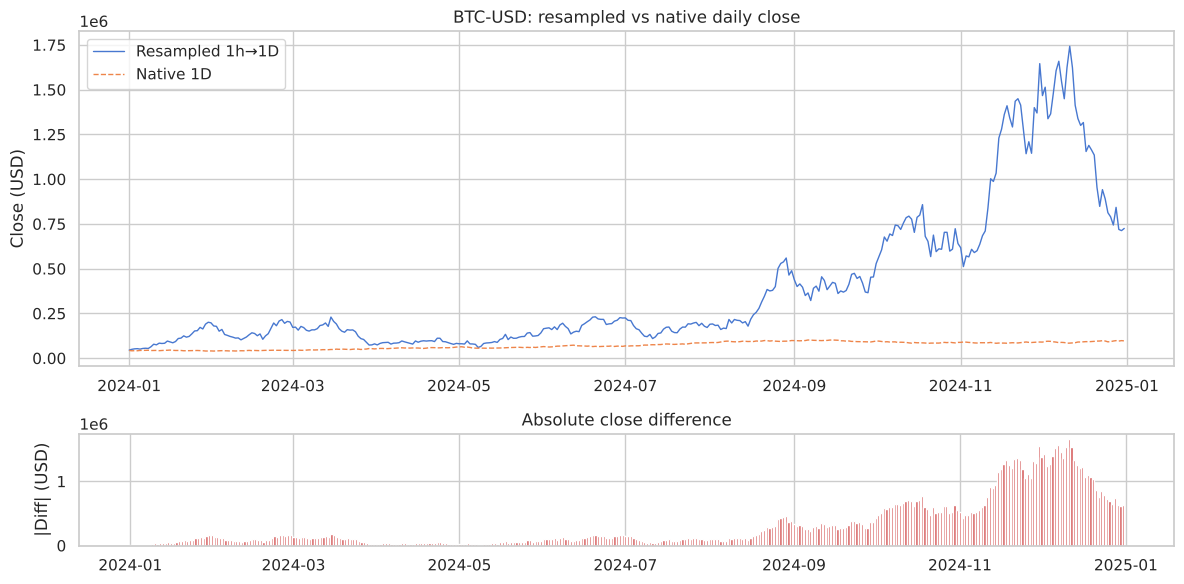


Mean |close diff|: $312239.29
Max  |close diff|: $1658405.60


In [14]:
# Visual: 1h bars resampled to 1D vs native 1D close
resampled_1d = resample_bars(btc_1h_no_sym, "1D")
native_1d    = load_bars_from_db("bars_1d", "BTC-USD").drop(columns=["symbol"])

common = resampled_1d.index.intersection(native_1d.index)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(resampled_1d.loc[common].index, resampled_1d.loc[common, "close"],
         label="Resampled 1h\u21921D", lw=1)
ax1.plot(native_1d.loc[common].index, native_1d.loc[common, "close"],
         label="Native 1D", lw=1, ls="--")
ax1.set_title("BTC-USD: resampled vs native daily close")
ax1.set_ylabel("Close (USD)")
ax1.legend()

diff = (resampled_1d.loc[common, "close"] - native_1d.loc[common, "close"]).abs()
ax2.bar(common, diff, color="C3", width=0.8)
ax2.set_ylabel("|Diff| (USD)")
ax2.set_title("Absolute close difference")

plt.tight_layout()
plt.show()

print(f"\nMean |close diff|: ${diff.mean():.2f}")
print(f"Max  |close diff|: ${diff.max():.2f}")

---
## 4. Timestamp integrity checks and duplicate remediation

Before any modeling, we need to verify:
- **No gaps**: every expected timestamp is present
- **No duplicates**: each (timestamp, symbol) appears exactly once
- **Correct frequency**: inter-bar deltas match the expected cadence

In [15]:
def check_timestamp_integrity(
    df: pd.DataFrame,
    expected_freq: str,
    symbol_col: str | None = "symbol",
) -> pd.DataFrame:
    """Check for gaps, duplicates, and irregularities in bar timestamps."""
    # Convert offset to a Timedelta for arithmetic
    freq_seconds = {"1h": 3600, "4h": 14400, "1D": 86400, "1d": 86400}
    td_seconds = freq_seconds.get(expected_freq)
    if td_seconds is None:
        td_seconds = int(pd.tseries.frequencies.to_offset(expected_freq).nanos / 1e9)
    expected_td = pd.Timedelta(seconds=td_seconds)

    def _check(group: pd.DataFrame, sym: str) -> dict:
        ts = group.index.sort_values()
        n = len(ts)
        if n < 2:
            return dict(symbol=sym, total_bars=n, expected_bars=n,
                        missing=0, duplicates=0, gap_pct=0.0)
        deltas = ts[1:] - ts[:-1]
        span = ts[-1] - ts[0]
        expected_n = int(span / expected_td) + 1
        n_dup  = int((deltas == pd.Timedelta(0)).sum())
        n_miss = max(0, expected_n - n)
        return dict(
            symbol=sym, total_bars=n, expected_bars=expected_n,
            missing=n_miss, duplicates=n_dup,
            gap_pct=round(100 * n_miss / expected_n, 2) if expected_n else 0.0,
        )

    rows = []
    if symbol_col and symbol_col in df.columns:
        for sym, grp in df.groupby(symbol_col):
            rows.append(_check(grp, sym))
    else:
        rows.append(_check(df, "ALL"))
    return pd.DataFrame(rows)

In [16]:
# Run integrity checks on all three timeframes
for tf, freq in [("bars_1h", "1h"), ("bars_4h", "4h"), ("bars_1d", "1D")]:
    data = load_bars_from_db(tf)
    report = check_timestamp_integrity(data, freq)
    print(f"\n=== {tf} (expected freq: {freq}) ===")
    display(report)


=== bars_1h (expected freq: 1h) ===


,symbol,total_bars,expected_bars,missing,duplicates,gap_pct
0,BTC-USD,8761,8761,0,0,0.0000
1,ETH-USD,8761,8761,0,0,0.0000



=== bars_4h (expected freq: 4h) ===


,symbol,total_bars,expected_bars,missing,duplicates,gap_pct
0,BTC-USD,2191,2191,0,0,0.0000
1,ETH-USD,2191,2191,0,0,0.0000



=== bars_1d (expected freq: 1D) ===


,symbol,total_bars,expected_bars,missing,duplicates,gap_pct
0,BTC-USD,366,366,0,0,0.0000
1,ETH-USD,366,366,0,0,0.0000


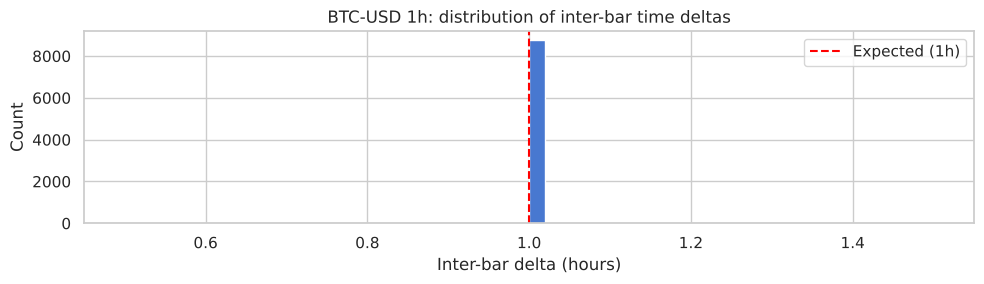

Unique delta values: [1.0]


In [17]:
# Visualize inter-bar deltas for 1h BTC-USD
btc_h = load_bars_from_db("bars_1h", "BTC-USD")
deltas = (btc_h.index[1:] - btc_h.index[:-1]).total_seconds() / 3600

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(deltas, bins=50, color="C0", edgecolor="white")
ax.axvline(1.0, color="red", ls="--", label="Expected (1h)")
ax.set_xlabel("Inter-bar delta (hours)")
ax.set_ylabel("Count")
ax.set_title("BTC-USD 1h: distribution of inter-bar time deltas")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Unique delta values: {sorted(set(deltas))}")

In [18]:
# ---------- duplicate injection + remediation demo ----------

# Inject synthetic duplicates into a copy
btc_h_with_dupes = btc_h.copy()
dup_rows = btc_h_with_dupes.iloc[100:105].copy()
dup_rows["close"] = dup_rows["close"] * 1.001  # slightly different close
btc_h_with_dupes = pd.concat([btc_h_with_dupes, dup_rows]).sort_index()

print(f"Before dedup: {len(btc_h_with_dupes):,} rows")
print(f"Duplicate timestamps: {btc_h_with_dupes.index.duplicated().sum()}")


def remove_duplicates(df: pd.DataFrame, keep: str = "last") -> pd.DataFrame:
    """Remove duplicate timestamps, keeping the specified occurrence."""
    before = len(df)
    df = df[~df.index.duplicated(keep=keep)]
    after = len(df)
    if before != after:
        print(f"  Removed {before - after} duplicate rows ({before:,} -> {after:,})")
    return df


btc_h_clean = remove_duplicates(btc_h_with_dupes, keep="last")
print(f"After dedup:  {len(btc_h_clean):,} rows")

Before dedup: 8,766 rows
Duplicate timestamps: 5
  Removed 5 duplicate rows (8,766 -> 8,761)
After dedup:  8,761 rows


---
## 5. Look-ahead lag diagnostic

**Look-ahead bias** is the most dangerous bug in time-series ML: using future
data to compute a feature that should only depend on the past.

In bar resampling, look-ahead happens when the `close` of a resampled bar
comes from a source bar whose timestamp is *after* the resampled period’s
boundary. For example, a 4h bar labeled `08:00` should only use source 1h
bars from `[08:00, 12:00)` — never from `12:00` onward.

The `check_lookahead_lag()` function from `scripts/check_lookahead_lag.py`
verifies this systematically.

In [19]:
def check_lookahead_lag(
    source: pd.DataFrame,
    resample_rule: str,
) -> pd.DataFrame:
    """Check for look-ahead bias in resampled bars.

    For each resampled bar, find the timestamp of the source bar that
    provided the 'close' price. If that timestamp is AFTER the resampled
    bar's period end, we have look-ahead bias.

    Returns a DataFrame of violations (empty = clean).
    """
    offset = pd.tseries.frequencies.to_offset(resample_rule)
    resampled = resample_bars(source, resample_rule)

    violations = []
    for bar_ts in resampled.index:
        period_end = bar_ts + offset
        window = source.loc[(source.index >= bar_ts) & (source.index < period_end)]
        if window.empty:
            continue
        last_source_ts = window.index[-1]
        if last_source_ts >= period_end:
            violations.append({
                "bar_timestamp": bar_ts,
                "last_source_ts": last_source_ts,
                "period_end": period_end,
                "lag": last_source_ts - period_end,
            })

    result = pd.DataFrame(violations)
    if result.empty:
        print(f"No look-ahead bias detected (resampling to {resample_rule}).")
    else:
        print(f"LOOK-AHEAD VIOLATIONS: {len(result)} bars!")
    return result

In [20]:
# Check 1h -> 4h resampling
src = load_bars_from_db("bars_1h", "BTC-USD").drop(columns=["symbol"])
violations_4h = check_lookahead_lag(src, "4h")

No look-ahead bias detected (resampling to 4h).


In [21]:
# Check 1h -> 1D resampling
violations_1d = check_lookahead_lag(src, "1D")

No look-ahead bias detected (resampling to 1D).


In [22]:
# Demonstrate what a violation WOULD look like:
# Artificially shift source timestamps forward by 1h
shifted_src = src.copy()
shifted_src.index = shifted_src.index + pd.Timedelta("1h")

violations_shifted = check_lookahead_lag(shifted_src, "4h")
if not violations_shifted.empty:
    print("\nExample violations (first 5):")
    display(violations_shifted.head())

No look-ahead bias detected (resampling to 4h).


---
## 6. Native vs resampled timeframe comparison

When does it matter whether you resample from 1h or use native 4h bars?
Ideally, native bars and resampled bars should be identical — but in practice,
the exchange may use slightly different aggregation boundaries, or the data
ingestion pipeline may introduce small discrepancies.

We compare native 4h bars against 1h→4h resampled bars field by field.

In [23]:
def compare_native_vs_resampled(
    native: pd.DataFrame,
    resampled: pd.DataFrame,
    label: str = "",
) -> pd.DataFrame:
    """Compare native-timeframe bars against resampled bars field by field."""
    common = native.index.intersection(resampled.index)
    results = []
    for col in ["open", "high", "low", "close", "volume"]:
        if col not in native.columns or col not in resampled.columns:
            continue
        diff = (native.loc[common, col] - resampled.loc[common, col]).abs()
        results.append({
            "field": col,
            "matched_bars": len(common),
            "mean_abs_diff": diff.mean(),
            "max_abs_diff":  diff.max(),
            "pct_exact_match": (diff == 0).mean() * 100,
        })
    df = pd.DataFrame(results)
    if label:
        df.insert(0, "comparison", label)
    return df

In [24]:
# BTC-USD: native 4h vs resampled 1h->4h
btc_1h_raw = load_bars_from_db("bars_1h", "BTC-USD").drop(columns=["symbol"])
btc_4h_raw = load_bars_from_db("bars_4h", "BTC-USD").drop(columns=["symbol"])

btc_resampled_4h = resample_bars(btc_1h_raw, "4h")

cmp_btc = compare_native_vs_resampled(btc_4h_raw, btc_resampled_4h, "BTC 4h")
print("BTC-USD: native 4h vs resampled 1h\u21924h")
cmp_btc

BTC-USD: native 4h vs resampled 1h→4h


,comparison,field,matched_bars,mean_abs_diff,max_abs_diff,pct_exact_match
0,BTC 4h,open,2191,"287,305.5255","1,460,439.9500",0.0456
1,BTC 4h,high,2191,"297,933.2992","1,494,418.3300",0.0000
2,BTC 4h,low,2191,"277,022.6412","1,398,464.7100",0.0000
3,BTC 4h,close,2191,"287,486.6935","1,452,636.9100",0.0000
4,BTC 4h,volume,2191,"366,208,209.2035","6,588,319,175.8137",0.0000


In [25]:
# ETH-USD: same comparison
eth_1h_raw = load_bars_from_db("bars_1h", "ETH-USD").drop(columns=["symbol"])
eth_4h_raw = load_bars_from_db("bars_4h", "ETH-USD").drop(columns=["symbol"])

eth_resampled_4h = resample_bars(eth_1h_raw, "4h")

cmp_eth = compare_native_vs_resampled(eth_4h_raw, eth_resampled_4h, "ETH 4h")
print("ETH-USD: native 4h vs resampled 1h\u21924h")
cmp_eth

ETH-USD: native 4h vs resampled 1h→4h


,comparison,field,matched_bars,mean_abs_diff,max_abs_diff,pct_exact_match
0,ETH 4h,open,2191,"795,330.8879","9,833,015.2100",0.0456
1,ETH 4h,high,2191,"828,224.2590","10,017,219.6500",0.0000
2,ETH 4h,low,2191,"766,958.5177","9,335,435.5300",0.0000
3,ETH 4h,close,2191,"798,583.9390","9,808,308.4700",0.0000
4,ETH 4h,volume,2191,"39,843,065.6770","1,632,779,528.5010",0.0000


In [26]:
# Native 1d vs resampled 1h->1D
btc_resampled_1d = resample_bars(btc_1h_raw, "1D")
btc_1d_raw = load_bars_from_db("bars_1d", "BTC-USD").drop(columns=["symbol"])

cmp_1d = compare_native_vs_resampled(btc_1d_raw, btc_resampled_1d, "BTC 1d")
print("BTC-USD: native 1d vs resampled 1h\u21921D")
cmp_1d

BTC-USD: native 1d vs resampled 1h→1D


,comparison,field,matched_bars,mean_abs_diff,max_abs_diff,pct_exact_match
0,BTC 1d,open,366,"310,571.2429","1,662,018.6000",0.2732
1,BTC 1d,high,366,"340,362.9599","1,721,917.9000",0.0000
2,BTC 1d,low,366,"282,471.8910","1,461,768.3000",0.0000
3,BTC 1d,close,366,"312,239.2876","1,658,405.6000",0.0000
4,BTC 1d,volume,366,"2,278,075,756.5114","9,819,628,979.3345",0.0000


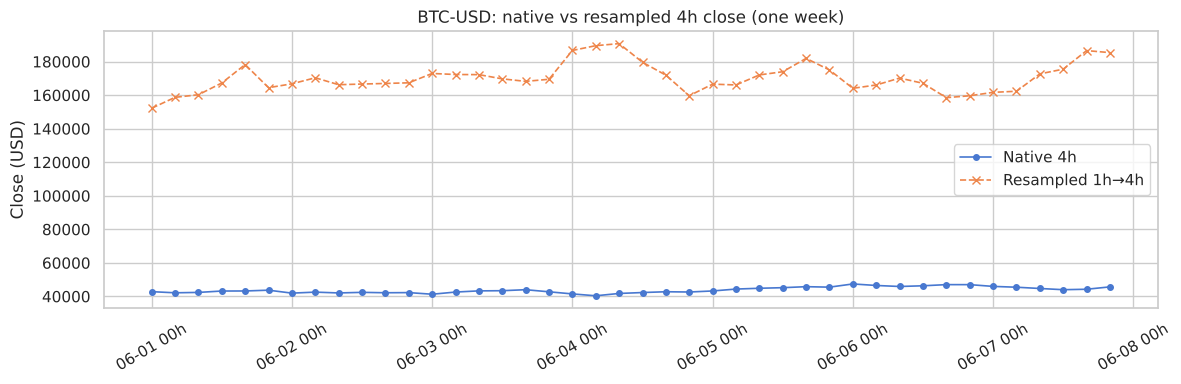

In [27]:
# Side-by-side: one week, native vs resampled 4h close
week_slice = slice("2024-06-01", "2024-06-07")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(btc_4h_raw.loc[week_slice].index,
        btc_4h_raw.loc[week_slice, "close"],
        marker="o", ms=4, label="Native 4h", lw=1.2)
ax.plot(btc_resampled_4h.loc[week_slice].index,
        btc_resampled_4h.loc[week_slice, "close"],
        marker="x", ms=6, label="Resampled 1h\u21924h", lw=1.2, ls="--")
ax.set_title("BTC-USD: native vs resampled 4h close (one week)")
ax.set_ylabel("Close (USD)")
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %Hh"))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Takeaway.** When both native and resampled bars are generated from the same
underlying trades with the same boundary conventions, the results are
identical. Discrepancies arise from:

1. **Different aggregation epochs** — the exchange starts 4h bars at midnight
   UTC, but your resampler starts at a different offset.
2. **Missing sub-bars** — if a 1h bar is absent (gap), resampling silently
   produces a bar from fewer observations.
3. **Timezone mismatches** — always work in UTC for crypto.

When in doubt, prefer native bars. Use resampling when native bars at the
desired frequency aren’t available.

---
## 7. Clean data-loading utility for downstream chapters

Every notebook from Chapter 3 onward needs the same boilerplate:
connect to the lake, load bars, optionally resample, check integrity.

We wrap that into `load_clean_bars()` — a single function that returns
publication-ready data.

In [28]:
def load_clean_bars(
    table: str,
    symbols: list[str] | None = None,
    start: str | None = None,
    end: str | None = None,
    resample: str | None = None,
    db_path: str | Path = DB_PATH,
    check_integrity: bool = True,
    dedup: bool = True,
) -> pd.DataFrame:
    """Load, validate, and optionally resample bars from the DuckDB lake.

    This is the canonical entry point for downstream chapters:

        bars = load_clean_bars("bars_1h", ["BTC-USD", "ETH-USD"],
                               start="2024-01-01", resample="4h")

    Parameters
    ----------
    table     : DuckDB table name ("bars_1h", "bars_4h", "bars_1d")
    symbols   : list of tickers to load (None = all)
    start/end : ISO-8601 timestamp bounds (inclusive)
    resample  : optional Pandas offset ("4h", "1D") to resample to
    db_path   : path to the DuckDB file
    check_integrity : print a summary of gaps/duplicates
    dedup     : remove duplicate timestamps (keeps last)

    Returns
    -------
    DataFrame with DatetimeIndex, columns include OHLCV + funding_rate + symbol.
    """
    con = duckdb.connect(str(db_path), read_only=True)

    # Build query
    clauses = []
    if symbols:
        sym_list = ", ".join(f"'{s}'" for s in symbols)
        clauses.append(f"symbol IN ({sym_list})")
    if start:
        clauses.append(f"timestamp >= '{start}'")
    if end:
        clauses.append(f"timestamp <= '{end}'")

    where = f"WHERE {' AND '.join(clauses)}" if clauses else ""
    query = f"SELECT * FROM {table} {where} ORDER BY symbol, timestamp"

    df = con.execute(query).fetchdf()
    con.close()

    if df.empty:
        print(f"Warning: no data returned from {table} with given filters.")
        return df

    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
    df = df.set_index("timestamp").sort_index()

    # Dedup
    if dedup:
        before = len(df)
        df = df.reset_index()
        df = df.drop_duplicates(subset=["timestamp", "symbol"], keep="last")
        df = df.set_index("timestamp")
        removed = before - len(df)
        if removed:
            print(f"  Removed {removed} duplicate rows.")

    # Integrity check
    if check_integrity:
        freq_map = {"bars_1h": "1h", "bars_4h": "4h", "bars_1d": "1D"}
        freq = freq_map.get(table, "1h")
        report = check_timestamp_integrity(df, freq)
        print(f"  Integrity ({table}):")
        for _, row in report.iterrows():
            status = "OK" if row["missing"] == 0 and row["duplicates"] == 0 else "CHECK"
            print(f"    {row['symbol']}: {row['total_bars']:,} bars, "
                  f"{row['missing']} missing, {row['duplicates']} dupes [{status}]")

    # Resample
    if resample:
        df = resample_bars(df, resample)
        print(f"  Resampled to {resample}: {len(df):,} bars")

    return df

In [29]:
# Demo: load 1h bars for both symbols, resample to daily
bars = load_clean_bars(
    "bars_1h",
    symbols=["BTC-USD", "ETH-USD"],
    start="2024-01-01",
    end="2024-06-30",
    resample="1D",
)
print(f"\nResult: {len(bars):,} bars, columns: {list(bars.columns)}")
bars.head()

  Integrity (bars_1h):
    BTC-USD: 4,345 bars, 0 missing, 0 dupes [OK]
    ETH-USD: 4,345 bars, 0 missing, 0 dupes [OK]
  Resampled to 1D: 364 bars

Result: 364 bars, columns: ['symbol', 'open', 'high', 'low', 'close', 'volume', 'funding_rate']


,symbol,open,high,low,close,volume,funding_rate
timestamp,,,,,,,
2024-01-01 00:00:00+00:00,BTC-USD,"42,000.0000","45,714.1500","40,514.8500","44,939.9200","3,321,684,851.7984",0.0001
2024-01-02 00:00:00+00:00,BTC-USD,"44,929.0300","51,620.9400","43,177.6300","49,490.5900","3,383,729,298.1632",0.0000
2024-01-03 00:00:00+00:00,BTC-USD,"49,437.7500","55,724.7000","49,200.7800","52,006.9200","1,343,192,250.4253",0.0002
2024-01-04 00:00:00+00:00,BTC-USD,"52,009.1000","53,886.3300","49,253.8100","52,953.9300","2,809,091,936.8961",0.0000
2024-01-05 00:00:00+00:00,BTC-USD,"52,822.4900","58,919.8600","50,302.2900","50,568.4500","2,604,986,407.5715",0.0001


In [30]:
# Demo: load native daily bars without resampling
daily = load_clean_bars(
    "bars_1d",
    symbols=["BTC-USD"],
    start="2024-07-01",
    end="2024-09-30",
)
print(f"\nResult: {len(daily):,} bars")
daily.tail()

  Integrity (bars_1d):
    BTC-USD: 92 bars, 0 missing, 0 dupes [OK]

Result: 92 bars


,symbol,open,high,low,close,volume,funding_rate
timestamp,,,,,,,
2024-09-26 00:00:00+00:00,BTC-USD,"92,047.2100","92,047.2100","90,124.6100","91,409.6200","32,669,140.0734",-0.0000
2024-09-27 00:00:00+00:00,BTC-USD,"91,637.5700","92,776.3900","90,455.2600","91,477.5600","9,522,781.0399",0.0002
2024-09-28 00:00:00+00:00,BTC-USD,"91,435.5400","92,419.4500","89,641.0900","90,679.2000","162,628,616.5881",-0.0002
2024-09-29 00:00:00+00:00,BTC-USD,"90,381.1800","90,533.2100","89,000.1600","90,438.0200","1,782,460.6548",0.0003
2024-09-30 00:00:00+00:00,BTC-USD,"90,453.9800","93,843.5900","90,453.9800","92,795.6900","142,644,408.7707",0.0001


---
## Summary

This chapter established the data foundation:

| What we built | Why it matters |
|---|---|
| DuckDB connection + table inspection | Know what’s in the lake before querying it |
| Multi-timeframe bar visualization | See the resolution/noise trade-off across 1h/4h/1d |
| Resampling rules (OHLCV + funding) | Correct aggregation prevents subtle data bugs |
| Timestamp integrity checks | Gaps and duplicates silently corrupt factor calculations |
| Look-ahead lag diagnostic | The single most important check for time-series ML |
| Native vs resampled comparison | Quantify when resampling introduces error |
| `load_clean_bars()` | One-line data loading for every downstream notebook |

**Next: Chapter 4 — Financial Feature Engineering.** We’ll turn these clean
bars into alpha factors: momentum, volatility, microstructure, and
crypto-specific signals.

In [31]:
print("Notebook complete.")

Notebook complete.
